<a href="https://colab.research.google.com/github/iansmena/Inteligencia-Artificial---Practicas/blob/main/Practica03_El_Perceptron.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Practica 3: El Perceptrón
**Inteligencia Artificial — 6to Nivel**

**Estudiante:** Ian Sebastián Mena

**Docente:** Rodrigo Tufiño

**Fecha:** 22/11/2026

Celda de librerías: ejecutar antes de iniciar. Solo se usa `random` (librería estándar) y `matplotlib` para graficar; no se usa ninguna librería de machine learning.

In [1]:
import random
import matplotlib.pyplot as plt

random.seed(42)

print("Librerias cargadas correctamente")

Librerias cargadas correctamente


# FASE 1. Exploración del Dataset

## 1.1 Carga del Dataset

In [2]:
X = [
    [1, 7], [1, 3], [3, 4], [4, 6], [4, 2], [6, 6], [6, 2],
    [6, 0], [7, 4], [9, 3], [9, 1], [11, 1], [12, 3], [16, 2],
    [4, 8], [6, 8], [8, 9], [9, 7], [10, 11], [12, 9], [12, 6],
    [14, 7], [16, 4]
]

y = [-1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
      1,  1,  1,  1,  1,  1,  1,  1,  1]

print("X =", X)
print("y =", y)

X = [[1, 7], [1, 3], [3, 4], [4, 6], [4, 2], [6, 6], [6, 2], [6, 0], [7, 4], [9, 3], [9, 1], [11, 1], [12, 3], [16, 2], [4, 8], [6, 8], [8, 9], [9, 7], [10, 11], [12, 9], [12, 6], [14, 7], [16, 4]]
y = [-1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


## Actividad 1.a:

### Inspección inicial

In [3]:
total = 0
for fila in X:
    total += 1

n_variables = len(X[0])

clases = []
for etiqueta in y:
    if etiqueta not in clases:
        clases.append(etiqueta)

conteo = {}
for etiqueta in y:
    if etiqueta in conteo:
        conteo[etiqueta] += 1
    else:
        conteo[etiqueta] = 1

print(f"Numero total de instancias: {total}")
print(f"Variables de entrada:        {n_variables} (x1, x2)")
print(f"Numero de clases:            {len(clases)} -> {clases}")
for c in clases:
    print(f"  Puntos de la clase {c:>2}:     {conteo[c]}")

Numero total de instancias: 23
Variables de entrada:        2 (x1, x2)
Numero de clases:            2 -> [-1, 1]
  Puntos de la clase -1:     14
  Puntos de la clase  1:     9


**P1. ¿Qué representa cada fila de X? ¿Qué representa cada valor del vector y? ¿Por qué este problema se considera de clasificación binaria?**

*Respuesta:* Cada fila de X es un punto del plano, con sus dos coordenadas x1 y x2. Cada valor de y es la clase de ese punto (esta en la misma posicion que su fila en X) y solo puede ser -1 o 1. Por eso es clasificacion binaria: solo hay dos clases posibles. En la inspeccion salieron 23 instancias, 2 variables y 2 clases, con 14 puntos en la clase -1 y 9 en la clase 1.

## Actividad 1.b:

### Separación visual de las clases

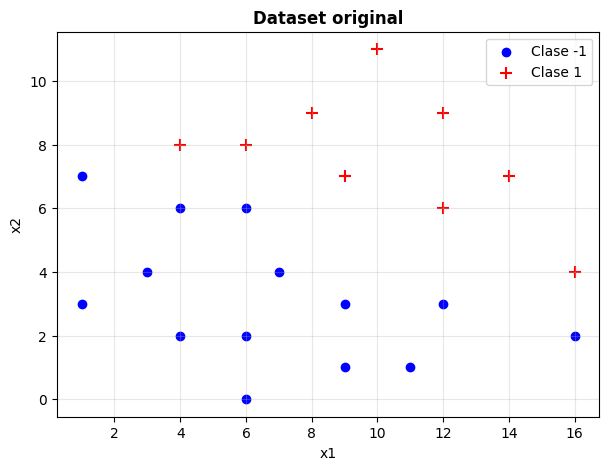

In [4]:
def plot_dataset(X, y, title):
    x1_neg, x2_neg, x1_pos, x2_pos = [], [], [], []
    for (x1, x2), etiqueta in zip(X, y):
        if etiqueta == -1:
            x1_neg.append(x1)
            x2_neg.append(x2)
        else:
            x1_pos.append(x1)
            x2_pos.append(x2)

    plt.figure(figsize=(7, 5))
    plt.scatter(x1_neg, x2_neg, color="blue", marker="o", label="Clase -1")
    plt.scatter(x1_pos, x2_pos, color="red", marker="+", s=80, label="Clase 1")
    plt.title(title, fontweight="bold")
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

plot_dataset(X, y, "Dataset original")

**P2. Observando únicamente la gráfica, ¿parece posible separar las dos clases mediante una sola recta? Justifica tu respuesta.**

*Respuesta:* Si. En la grafica las cruces rojas (clase 1) estan arriba y a la derecha, y los circulos azules (clase -1) quedan abajo, asi que una recta inclinada que baje mas o menos desde (0, 9) hasta (17, 2) los dejaria separados. Lo que si se nota es que hay puntos de clases distintas muy pegados, como (6, 6) y (6, 8), (1, 7) y (4, 8), o (16, 2) y (16, 4). O sea, se pueden separar con una recta, pero va a tener poco espacio para pasar.

# FASE 2. Fundamento del Perceptrón

El perceptrón calcula la suma ponderada $z = w_0 + w_1x_1 + w_2x_2$ y le aplica la función escalón bipolar: $\hat{y} = 1$ si $z \geq 0$, y $\hat{y} = -1$ si $z < 0$. La frontera de decisión es la recta $w_0 + w_1x_1 + w_2x_2 = 0$.

## Actividad 2.a:

### Vector de pesos

In [5]:
def initialize_weights():
    return [random.uniform(-0.5, 0.5) for _ in range(3)]

print("Ejemplo de pesos:", [round(p, 4) for p in initialize_weights()])

Ejemplo de pesos: [0.1394, -0.475, -0.225]


**P3. ¿Por qué el vector de pesos tiene tres valores si cada instancia de entrada solo tiene dos variables? ¿Qué función cumple el bias en el modelo?**

*Respuesta:* Porque el tercer valor es el bias (w0), que no va con ninguna variable del dataset; se puede ver como un peso cuya entrada siempre vale 1. w1 y w2 deciden la inclinacion de la recta y el bias la desplaza. Si no estuviera, la frontera seria w1*x1 + w2*x2 = 0 y pasaria siempre por el origen (0, 0). Aqui eso no funcionaria, porque la recta que separa las clases corta el eje x2 cerca de 8.6, bastante lejos del origen.

## Actividad 2.b:

### Función de activación

In [6]:
def activation(z):
    if z >= 0:
        return 1
    return -1

for z in [-2.5, 0, 3.1]:
    print(f"activation({z}) = {activation(z)}")

activation(-2.5) = -1
activation(0) = 1
activation(3.1) = 1


**P4. ¿Por qué en esta práctica se utilizan las etiquetas -1 y 1 en lugar de 0 y 1? ¿Qué ventaja tiene esta representación para el algoritmo del perceptrón?**

*Respuesta:* Porque la funcion escalon bipolar devuelve -1 o 1, entonces la prediccion y la etiqueta real quedan en la misma escala y se pueden comparar directamente. La ventaja se ve en la regla de actualizacion: (y - ŷ) vale 0 cuando acierta, +2 cuando debia salir 1 y salio -1, y -2 en el caso contrario. El signo ya dice hacia donde hay que mover la recta y las dos clases se corrigen con la misma fuerza. Tambien es facil de leer: un punto esta bien clasificado cuando y y z tienen el mismo signo.

## Actividad 2.c:

### Cálculo de salida

In [7]:
def perceptron_compute(x, w):
    z = w[0] + w[1] * x[0] + w[2] * x[1]
    return activation(z)

In [8]:
w_prueba = [-1.0, 0.2, 0.3]

for i in [0, 9, 18]:
    x = X[i]
    z = w_prueba[0] + w_prueba[1] * x[0] + w_prueba[2] * x[1]
    salida = perceptron_compute(x, w_prueba)
    print(f"x = {x} | z = {w_prueba[0]} + {w_prueba[1]}*{x[0]} + {w_prueba[2]}*{x[1]} = {z:.2f}"
          f" -> salida = {salida:>2} | real = {y[i]:>2}")

x = [1, 7] | z = -1.0 + 0.2*1 + 0.3*7 = 1.30 -> salida =  1 | real = -1
x = [9, 3] | z = -1.0 + 0.2*9 + 0.3*3 = 1.70 -> salida =  1 | real = -1
x = [10, 11] | z = -1.0 + 0.2*10 + 0.3*11 = 4.30 -> salida =  1 | real =  1


**P5. ¿Cuál es la diferencia entre la suma ponderada z y la salida final del perceptrón? ¿Por qué no basta con calcular solo z?**

*Respuesta:* z es solo un numero (positivo, negativo o cero) que indica de que lado de la frontera cae el punto y que tan lejos esta. La salida es la clase, que solo puede ser -1 o 1. Con z no alcanza porque un valor como 1.30 no se puede comparar con una etiqueta; hace falta la funcion de activacion para convertirlo en una decision. En la prueba manual se ve: [1, 7] da z = 1.30 y se clasifica como 1, aunque en realidad es -1, porque esos pesos de prueba no estan entrenados.

# FASE 3. Visualización de la Frontera de Decisión

Partiendo de $w_0 + w_1x_1 + w_2x_2 = 0$ y despejando $x_2$:

$$x_2 = -\frac{w_0 + w_1x_1}{w_2}$$

Si $w_2 = 0$ no se puede despejar $x_2$; en ese caso la recta es vertical: $x_1 = -\frac{w_0}{w_1}$.

## Actividad 3.a:

### Función de graficación

In [9]:
def perceptron_plot(X, y, w, title, ax=None):
    mostrar = ax is None
    if mostrar:
        fig, ax = plt.subplots(figsize=(7, 5))

    neg = [x for x, e in zip(X, y) if e == -1]
    pos = [x for x, e in zip(X, y) if e == 1]
    ax.scatter([p[0] for p in neg], [p[1] for p in neg], color="blue", marker="o", label="Clase -1")
    ax.scatter([p[0] for p in pos], [p[1] for p in pos], color="red", marker="+", s=80, label="Clase 1")

    x_min, x_max, y_min, y_max = -1, 18, -2, 13
    w0, w1, w2 = w

    if w2 != 0:
        x1_linea = [x_min, x_max]
        x2_linea = [-(w0 + w1 * x1) / w2 for x1 in x1_linea]
        ax.plot(x1_linea, x2_linea, color="green", linewidth=2, label="Frontera")
    elif w1 != 0:
        ax.axvline(-w0 / w1, color="green", linewidth=2, label="Frontera (vertical)")
    else:
        print("w1 y w2 son 0: no hay frontera que graficar")

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.legend(loc="upper left", fontsize=8)
    ax.grid(alpha=0.3)

    if mostrar:
        plt.show()

**P6. ¿Qué representa geométricamente la recta generada por el perceptrón? ¿Qué ocurre si los pesos iniciales son aleatorios?**

*Respuesta:* La recta son todos los puntos donde z = 0. Parte el plano en dos: de un lado z >= 0 y todo se clasifica como 1, y del otro z < 0 y todo sale -1. Si los pesos iniciales son aleatorios, la recta tambien aparece en cualquier posicion y con cualquier inclinacion, incluso fuera de la zona de los datos. Es solo el punto de partida; el entrenamiento es el que la va acomodando.

## Actividad 3.b:

### Gráfica con pesos iniciales

Pesos iniciales [w0, w1, w2]: [-0.2768, 0.2365, 0.1767]
Errores con la frontera inicial: 14 de 23


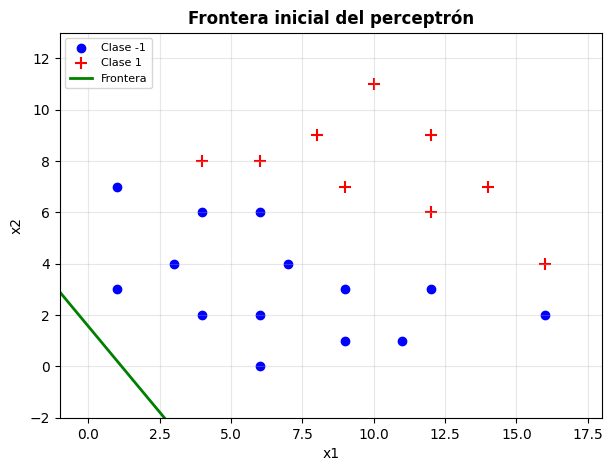

In [10]:
def count_errors(X, y, w):
    errores = 0
    for x, real in zip(X, y):
        if perceptron_compute(x, w) != real:
            errores += 1
    return errores

w_initial = initialize_weights()
print("Pesos iniciales [w0, w1, w2]:", [round(p, 4) for p in w_initial])
print(f"Errores con la frontera inicial: {count_errors(X, y, w_initial)} de {len(X)}")

perceptron_plot(X, y, w_initial, "Frontera inicial del perceptrón")

**P7. ¿La frontera inicial clasifica correctamente los puntos? ¿Por qué no deberíamos esperar que una frontera con pesos aleatorios sea correcta?**

*Respuesta:* No, falla en 14 de los 23 puntos. La recta queda en la esquina inferior izquierda y todos los puntos caen del lado positivo, entonces los 9 de la clase 1 aciertan de casualidad y los 14 de la clase -1 salen mal. No tendria por que ser correcta, porque los pesos aleatorios no saben nada de los datos. Ademas, los pesos iniciales estan entre -0.5 y 0.5 y la frontera que separa las clases necesita un bias de alrededor de -77, asi que acertar al azar es practicamente imposible.

**Explicación de la frontera de decisión:** La frontera es la recta $w_0 + w_1x_1 + w_2x_2 = 0$. Despejando queda $x_2 = -\frac{w_1}{w_2}x_1 - \frac{w_0}{w_2}$, donde la pendiente es $-w_1/w_2$ y el corte con el eje x2 es $-w_0/w_2$. Con los pesos iniciales [-0.2768, 0.2365, 0.1767] sale $x_2 = -1.338x_1 + 1.566$. Como w2 es positivo, lo que queda por encima de la recta da z >= 0 y se clasifica como 1, y como todos los puntos del dataset estan por encima, todos salen como clase 1.

# FASE 4. Entrenamiento del Perceptrón

Regla de actualización (solo cuando la predicción es incorrecta):

$$w_i \leftarrow w_i + \eta(y - \hat{y})x_i \qquad\qquad w_0 \leftarrow w_0 + \eta(y - \hat{y})$$

## Actividad 4.a, 4.b y 4.c:

### Función de aprendizaje con registro del error y de los pesos

Las tres actividades se resuelven en la misma función, porque el error (4.b) y los pesos (4.c) se registran dentro del ciclo de entrenamiento. La tasa de error de cada época es $E = \frac{\text{número de errores}}{\text{número total de instancias}}$.

In [11]:
def perceptron_learning(X, y, w, lr, max_epochs):
    w = w.copy()
    W_values = [w.copy()]
    E_values = []
    updates = 0
    epochs = 0

    while epochs < max_epochs:
        epochs += 1
        errores = 0

        for x, real in zip(X, y):
            pred = perceptron_compute(x, w)
            if pred != real:
                delta = lr * (real - pred)
                w[0] += delta
                w[1] += delta * x[0]
                w[2] += delta * x[1]
                errores += 1
                updates += 1

        E_values.append(errores / len(X))
        W_values.append(w.copy())

        if errores == 0:
            break

    return w, epochs, updates, W_values, E_values

**P8. ¿Por qué es necesario incluir un número máximo de épocas? ¿Qué podría ocurrir si el dataset no fuera linealmente separable?**

*Respuesta:* Porque el algoritmo solo para cuando una epoca completa sale sin errores, y nada asegura que eso vaya a pasar. El maximo de epocas es lo que garantiza que el ciclo termine. Si el dataset no fuera linealmente separable (por ejemplo, con un punto de la clase 1 metido entre los de la clase -1, o el caso del XOR), ninguna recta podria clasificar todo bien: siempre quedaria algun error y los pesos seguirian cambiando sin estabilizarse. Sin ese limite el entrenamiento nunca terminaria.

**P9. ¿Qué significa que la tasa de error llegue a cero?**

*Respuesta:* Que en esa epoca el perceptron clasifico bien todas las instancias de entrenamiento y no tuvo que corregir nada, asi que los pesos dejan de cambiar y el entrenamiento converge. Tambien confirma que el dataset si es linealmente separable, porque se encontro una recta que divide las dos clases.

Demostración de por qué se guarda una copia (Actividad 4.c):

In [12]:
w_demo = [0.0, 0.0, 0.0]
con_referencia, con_copia = [], []
for epoca in range(3):
    w_demo[0] += 1
    con_referencia.append(w_demo)
    con_copia.append(w_demo.copy())

print("Guardando la referencia:", con_referencia)
print("Guardando copias:       ", con_copia)

Guardando la referencia: [[3.0, 0.0, 0.0], [3.0, 0.0, 0.0], [3.0, 0.0, 0.0]]
Guardando copias:        [[1.0, 0.0, 0.0], [2.0, 0.0, 0.0], [3.0, 0.0, 0.0]]


**P10. ¿Por qué es importante guardar copias de los pesos y no solo el vector w? ¿Qué problema aparecería al intentar graficar la evolución del entrenamiento?**

*Respuesta:* Porque en Python las listas son mutables. Si se guarda w directamente, lo que queda guardado es una referencia al mismo objeto, y cuando el entrenamiento lo modifica cambian todas las entradas de W_values. En la demostracion se ve claro: guardando la referencia las tres entradas terminan en [3.0, 0.0, 0.0], mientras que con .copy() se conserva cada paso. Sin copias, las seis graficas de la Fase 7 mostrarian la misma recta final y no se podria ver como fue aprendiendo el modelo.

# FASE 5. Entrenamiento con tasa de aprendizaje 0.5

## Actividad 5.a:

### Entrena el modelo

In [13]:
w = initialize_weights()

final_w, epochs, updates, W_values, E_values = perceptron_learning(
    X,
    y,
    w,
    lr=0.5,
    max_epochs=1000
)

print(f"Pesos iniciales:   {[round(p, 4) for p in w]}")
print(f"Pesos finales:     {[round(p, 4) for p in final_w]}")
print(f"Numero de epocas:  {epochs}")
print(f"Actualizaciones:   {updates}")
print(f"Error final:       {E_values[-1]}")
print(f"\nPrimeras 10 tasas de error: {[round(e, 3) for e in E_values[:10]]}")
print(f"Ultimas 5 tasas de error:   {[round(e, 3) for e in E_values[-5:]]}")

Pesos iniciales:   [0.3922, -0.4131, -0.0781]
Pesos finales:     [-76.6078, 3.5869, 8.9219]
Numero de epocas:  115
Actualizaciones:   427
Error final:       0.0

Primeras 10 tasas de error: [0.043, 0.174, 0.174, 0.304, 0.261, 0.217, 0.304, 0.261, 0.174, 0.087]
Ultimas 5 tasas de error:   [0.174, 0.13, 0.087, 0.043, 0.0]


**P11. ¿El perceptrón logró converger? ¿Cómo puedes comprobarlo usando la lista E_values y la gráfica final?**

*Respuesta:* Si, convergio en 115 epocas con 427 actualizaciones. Se puede comprobar con E_values: el ultimo valor es 0.0 (las ultimas epocas fueron bajando 0.13, 0.087, 0.043 y 0.0) y el entrenamiento se detuvo mucho antes de llegar a las 1000 epocas. En la grafica de la frontera final tambien se ve que todos los circulos quedan de un lado y todas las cruces del otro, con 0 errores de 23.

## Actividad 5.b:

### Frontera final

Errores con la frontera final: 0 de 23


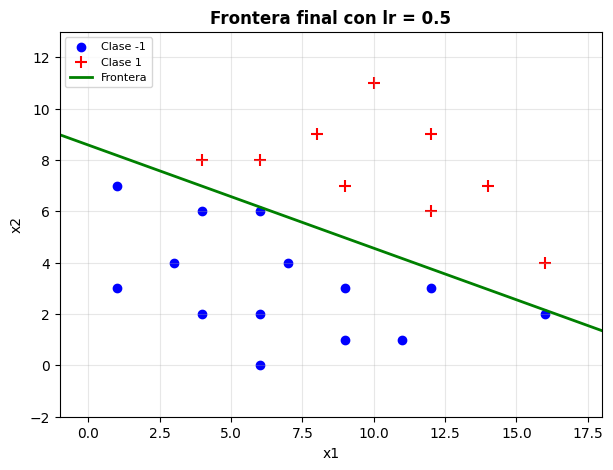

In [14]:
print(f"Errores con la frontera final: {count_errors(X, y, final_w)} de {len(X)}")
perceptron_plot(X, y, final_w, "Frontera final con lr = 0.5")

**P12. ¿La frontera final separa correctamente las dos clases? ¿Qué diferencias observas respecto a la frontera inicial?**

*Respuesta:* Si, separa las dos clases sin errores. La frontera inicial de este entrenamiento era casi vertical (pendiente -5.29), estaba pegada al borde izquierdo y fallaba en 9 puntos. La final baja de forma suave ($x_2 = -0.402x_1 + 8.586$) y pasa entre los dos grupos. Los pesos tambien crecieron bastante: empezaron por debajo de 0.5 y terminaron en [-76.61, 3.59, 8.92]. Lo que me llamo la atencion es que la recta pasa muy cerca de (6, 6) y (16, 2), entonces separa bien pero con muy poco margen.

# FASE 6. Predicción con Nuevas Instancias

## Actividad 6.a:

### Clasificación de nuevas instancias

In [15]:
X_test = [
    [5, 5],
    [10, 6],
    [6, 10]
]

y_test = [perceptron_compute(x, final_w) for x in X_test]

print(f"{'Instancia':<12} {'z':>10} {'Salida predicha':>17}")
print("-" * 41)
for x, pred in zip(X_test, y_test):
    z = final_w[0] + final_w[1] * x[0] + final_w[2] * x[1]
    print(f"{str(x):<12} {z:>10.2f} {pred:>17}")

Instancia             z   Salida predicha
-----------------------------------------
[5, 5]           -14.06                -1
[10, 6]           12.79                 1
[6, 10]           34.13                 1


**P13. ¿Las predicciones obtenidas son coherentes con la ubicación visual de los puntos respecto a la frontera de decisión?**

*Respuesta:* Si. Para cada punto vi por donde pasa la frontera en su valor de x1 y lo compare con su x2. En x1 = 5 la recta esta en x2 ≈ 6.58 y [5, 5] queda abajo, por eso sale -1 (z = -14.06). En x1 = 10 esta en x2 ≈ 4.57 y [10, 6] queda arriba, entonces sale 1 (z = 12.79). En x1 = 6 esta en x2 ≈ 6.17 y [6, 10] queda bastante arriba, tambien 1 (z = 34.13). En los tres casos el signo de z coincide con el lado de la recta donde se ve el punto.

## Actividad 6.b:

### Dataset extendido

Instancias originales: 23 -> Instancias extendidas: 26
Ultimas 3 filas agregadas: [([5, 5], -1), ([10, 6], 1), ([6, 10], 1)]


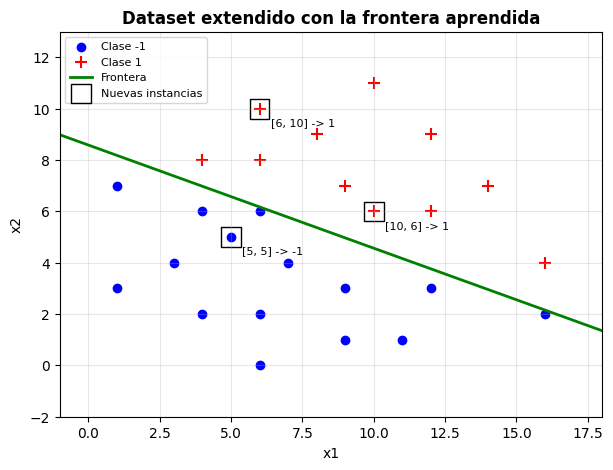

In [16]:
X_ext = [fila.copy() for fila in X] + [fila.copy() for fila in X_test]
y_ext = y.copy() + y_test

print(f"Instancias originales: {len(X)} -> Instancias extendidas: {len(X_ext)}")
print("Ultimas 3 filas agregadas:", list(zip(X_ext[-3:], y_ext[-3:])))

fig, ax = plt.subplots(figsize=(7, 5))
perceptron_plot(X_ext, y_ext, final_w, "Dataset extendido con la frontera aprendida", ax=ax)
ax.scatter([p[0] for p in X_test], [p[1] for p in X_test], s=200, facecolors="none",
           edgecolors="black", marker="s", label="Nuevas instancias")
for x, pred in zip(X_test, y_test):
    ax.annotate(f"{x} -> {pred}", (x[0], x[1]), textcoords="offset points", xytext=(8, -12), fontsize=8)
ax.legend(loc="upper left", fontsize=8)
plt.show()

**P14. ¿Las nuevas instancias quedaron ubicadas en la región esperada del plano? ¿Alguna predicción parece discutible? Justifica tu respuesta.**

*Respuesta:* Si, las tres quedaron donde se esperaba. [6, 10] es la mas clara: esta rodeada de cruces y es la mas lejana a la frontera. [5, 5] tiene cerca puntos de la clase -1 como (4, 6), (6, 6), (3, 4) y (7, 4), asi que tiene sentido que salga -1. La que me parece mas discutible es [10, 6], porque es la mas cercana a la frontera (a unas 1.33 unidades) y esta en la zona entre las dos clases. Igual sus vecinos mas cercanos, (9, 7) y (12, 6), son de clase 1, por lo que la prediccion es razonable. Eso si, si el perceptron hubiera terminado en otra recta valida, un punto en esa zona podria cambiar de clase.

# FASE 7. Evolución de la Frontera de Decisión

## Actividad 7.a:

### Seis estados del entrenamiento

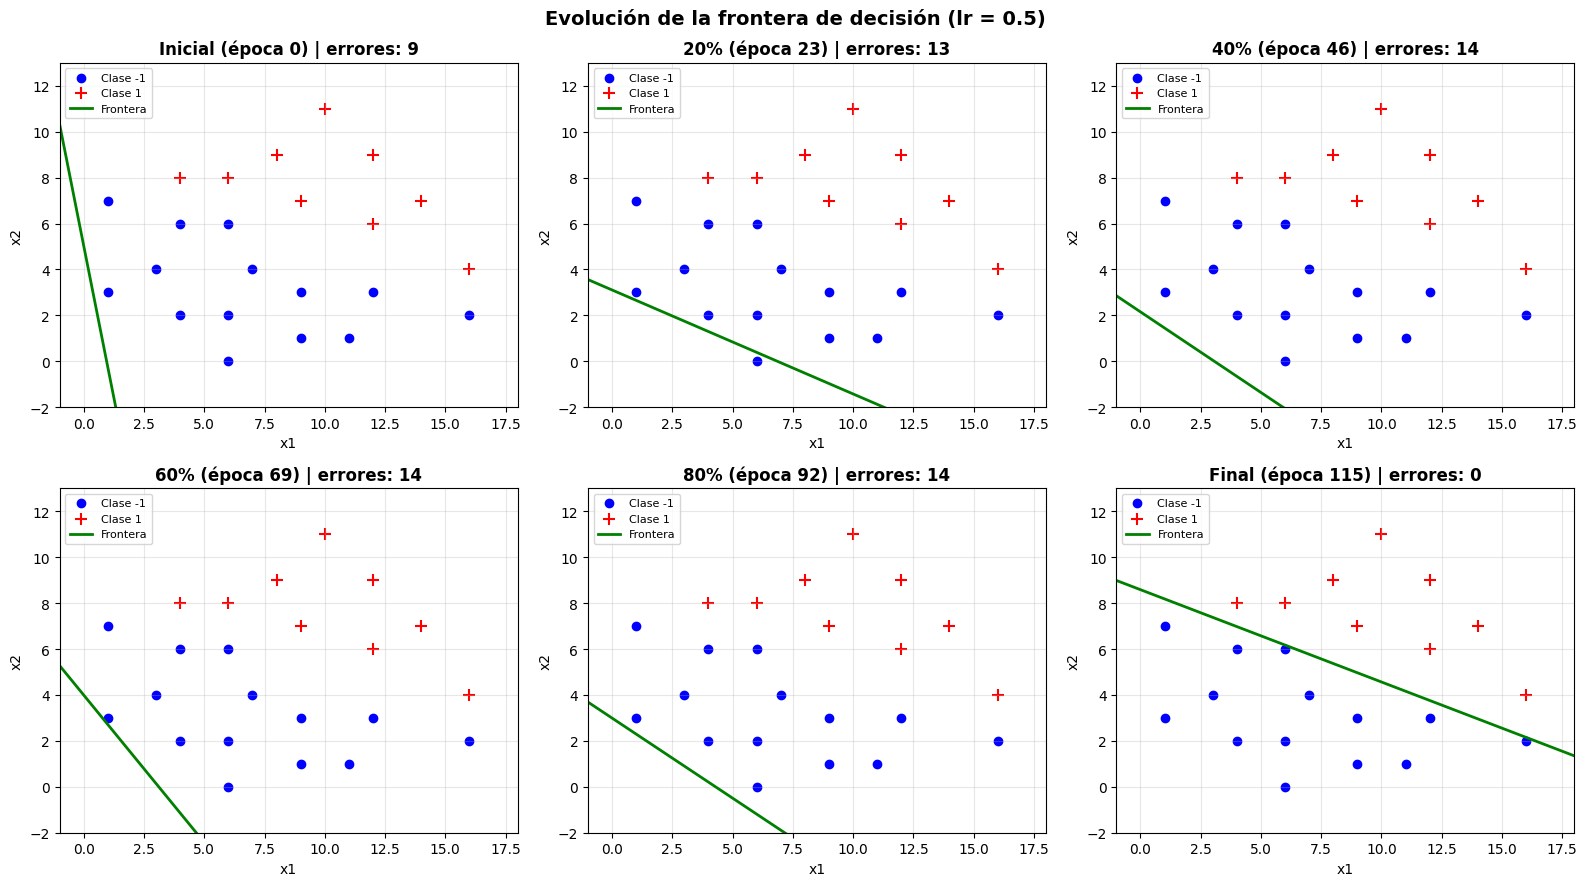

 Epoca         w0       w1       w2   pendiente -w1/w2   corte -w0/w2
     0      0.392   -0.413   -0.078             -5.290          5.023
    23    -24.608    3.587    7.922             -0.453          3.106
    46    -38.608   12.587   17.922             -0.702          2.154
    69    -51.608   16.587   12.922             -1.284          3.994
    92    -62.608   14.587   20.922             -0.697          2.992
   115    -76.608    3.587    8.922             -0.402          8.586


In [17]:
def plot_evolution(X, y, W_values, title):
    n_epocas = len(W_values) - 1

    if n_epocas < 5:
        indices = list(range(len(W_values)))
    else:
        indices = [round(p * n_epocas) for p in [0, 0.2, 0.4, 0.6, 0.8, 1.0]]
    etiquetas = ["Inicial", "20%", "40%", "60%", "80%", "Final"]

    fig, axes = plt.subplots(2, 3, figsize=(16, 9))
    axes = [ax for fila in axes for ax in fila]

    for k, (ax, idx) in enumerate(zip(axes, indices)):
        nombre = etiquetas[k] if n_epocas >= 5 else f"Estado {idx}"
        errores = count_errors(X, y, W_values[idx])
        perceptron_plot(X, y, W_values[idx], f"{nombre} (época {idx}) | errores: {errores}", ax=ax)

    for ax in axes[len(indices):]:
        ax.axis("off")

    plt.suptitle(title, fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()

    print(f"{'Epoca':>6} {'w0':>10} {'w1':>8} {'w2':>8} {'pendiente -w1/w2':>18} {'corte -w0/w2':>14}")
    for idx in indices:
        w0, w1, w2 = W_values[idx]
        pend = f"{-w1 / w2:.3f}" if w2 != 0 else "vertical"
        corte = f"{-w0 / w2:.3f}" if w2 != 0 else "-"
        print(f"{idx:>6} {w0:>10.3f} {w1:>8.3f} {w2:>8.3f} {pend:>18} {corte:>14}")

plot_evolution(X, y, W_values, "Evolución de la frontera de decisión (lr = 0.5)")

**P15. ¿Qué ocurre con la frontera de decisión a medida que se actualizan los pesos? ¿El cambio parece estable o brusco?**

*Respuesta:* La frontera no se acerca poco a poco a la solucion, va a saltos. En los estados intermedios la recta cambia de inclinacion varias veces (pendientes -5.29, -0.45, -0.70, -1.28, -0.70) y casi siempre se queda abajo a la izquierda, por debajo de los puntos; por eso en 20%, 40%, 60% y 80% tiene 13 o 14 errores. Recien al final se acomoda entre las dos clases y llega a 0 errores. El cambio es brusco porque cada correccion suma 2·lr·x a los pesos, y como x1 llega hasta 16, un solo error puede mover w1 hasta 16 unidades de golpe.

## Actividad 7.b:

### Interpretación geométrica

La recta despejada es $x_2 = -\frac{w_1}{w_2}x_1 - \frac{w_0}{w_2}$, entonces la **pendiente** es $-w_1/w_2$ y el **corte con el eje x2** es $-w_0/w_2$.

**P16. ¿Qué peso parece influir más en la inclinación de la recta? ¿Qué papel parece cumplir el bias en el desplazamiento de la frontera?**

*Respuesta:* La inclinacion depende de la relacion $-w_1/w_2$, pero el que mas vario en este entrenamiento fue w1 (paso por 3.59, 12.59, 16.59, 14.59 y volvio a 3.59), y esos saltos son los que hacian girar la recta. Tiene sentido, porque x1 llega hasta 16 y las correcciones sobre w1 son mas grandes. El bias es el que desplaza la recta: el corte con el eje es $-w_0/w_2$, asi que al cambiar w0 la recta se mueve en paralelo sin girar. En la tabla w0 baja casi de forma constante (0.39, -24.6, -38.6, -51.6, -62.6, -76.6), y eso es lo que fue subiendo la frontera hasta dejarla entre las clases. Tambien es el peso que mas lento cambia: con lr = 0.5 se mueve ±1 por actualizacion, mientras que w1 y w2 pueden cambiar hasta 16 y 11. Por eso hicieron falta tantas epocas.

**Comentario sobre la evolución observada:** Casi todo el entrenamiento la frontera estuvo por debajo de los datos, girando de un lado a otro con cada correccion, mientras el bias iba bajando poco a poco. Recien en las ultimas epocas el bias fue lo bastante negativo como para subir la recta hasta la zona entre las clases, y ahi la inclinacion se estabilizo y los errores llegaron a 0.

# FASE 8. Evolución del Error

## Actividad 8.a:

### Gráfica de error

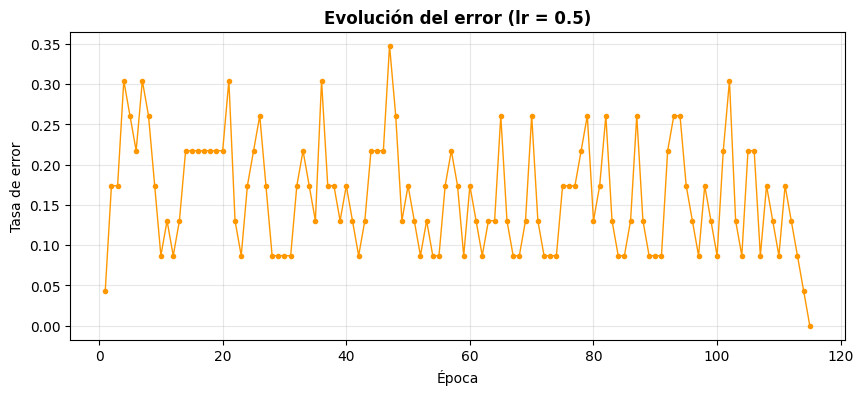

Cambios entre epocas -> sube: 41 | baja: 48 | igual: 25
Error maximo: 0.348 | Error final: 0.0


In [18]:
def plot_error(E_values, title):
    epocas = list(range(1, len(E_values) + 1))
    plt.figure(figsize=(10, 4))
    plt.plot(epocas, E_values, color="#FF9800", marker="o", markersize=3, linewidth=1)
    plt.title(title, fontweight="bold")
    plt.xlabel("Época")
    plt.ylabel("Tasa de error")
    plt.grid(alpha=0.3)
    plt.show()

plot_error(E_values, "Evolución del error (lr = 0.5)")

sube = sum(1 for a, b in zip(E_values, E_values[1:]) if b > a)
baja = sum(1 for a, b in zip(E_values, E_values[1:]) if b < a)
igual = sum(1 for a, b in zip(E_values, E_values[1:]) if b == a)
print(f"Cambios entre epocas -> sube: {sube} | baja: {baja} | igual: {igual}")
print(f"Error maximo: {max(E_values):.3f} | Error final: {E_values[-1]}")

**P17. ¿El error disminuye de forma continua en todas las épocas? Si no ocurre así, ¿por qué puede aumentar o mantenerse igual durante algunos momentos del entrenamiento?**

*Respuesta:* No. En las 115 epocas el error subio 41 veces, bajo 48 y se quedo igual 25, y estuvo oscilando entre 0.04 y 0.35 casi hasta el final. Esto pasa porque el perceptron corrige los pesos cada vez que se equivoca en una instancia y solo toma en cuenta esa instancia: al arreglar un punto la recta salta y puede dañar otros que ya estaban bien. No busca bajar el error total en cada paso; lo unico que se garantiza, si los datos son separables, es que en algun momento deja de equivocarse. Otro detalle es que E_values cuenta los errores mientras los pesos van cambiando dentro de la epoca, por eso no coincide con los errores de los pesos al final de esa epoca (en la Fase 7 hay estados con 14 errores aunque la tasa de esa epoca era menor).

## Actividad 8.b:

### Análisis de convergencia

In [19]:
print(f"Ultima epoca: {epochs} | Tasa de error: {E_values[-1]}")
print(f"Pesos de la ultima epoca: {[round(p, 4) for p in W_values[-1]]}")
print(f"Pesos de la penultima:    {[round(p, 4) for p in W_values[-2]]}  (iguales -> no hubo actualizaciones)")

Ultima epoca: 115 | Tasa de error: 0.0
Pesos de la ultima epoca: [-76.6078, 3.5869, 8.9219]
Pesos de la penultima:    [-76.6078, 3.5869, 8.9219]  (iguales -> no hubo actualizaciones)


**P18. ¿Qué significa que el error final sea igual a cero? ¿Significa que el modelo es perfecto para cualquier dato futuro? Justifica tu respuesta.**

*Respuesta:* Significa que con los pesos finales todas las instancias de entrenamiento quedan bien clasificadas, pero no que el modelo sea perfecto para datos nuevos. Solo se evaluo con los mismos 23 puntos con los que se entreno, no con datos de prueba. Ademas, el perceptron se detiene en la primera recta que separa los datos, no en la mejor: la frontera final pasa a 0.14 unidades de (16, 2) y a 0.16 de (6, 6), entonces un punto nuevo que este un poco corrido podria clasificarse mal. Un metodo que maximice el margen, como SVM, buscaria una recta mas centrada.

**Análisis de la convergencia:** Con lr = 0.5 el entrenamiento convergio en la epoca 115, despues de 427 actualizaciones. Durante casi todo el proceso el error no tuvo una tendencia clara a bajar: oscilo entre 0.04 y 0.35 y recien en las ultimas cuatro epocas cayo hasta 0. Los pesos de las dos ultimas epocas son iguales, lo que confirma que en la ultima no hubo ninguna correccion. Tardo tanto porque las clases tienen poco espacio entre ellas y el bias tenia que llegar a un valor grande (-76.6) moviendose de 1 en 1.

# FASE 9. Comparación de Tasas de Aprendizaje

## Actividad 9.a:

### Entrenamiento comparativo

In [20]:
w_base = w.copy()
print(f"Pesos iniciales comunes: {[round(p, 4) for p in w_base]}\n")

resultados = {}
for lr in [0.3, 0.5, 0.8]:
    fw, ep, up, Wv, Ev = perceptron_learning(X, y, w_base.copy(), lr=lr, max_epochs=1000)
    resultados[lr] = {"w": fw, "epocas": ep, "updates": up, "W_values": Wv, "E_values": Ev}
    print(f"lr = {lr}: epocas = {ep}, actualizaciones = {up}, error final = {Ev[-1]}, "
          f"pesos finales = {[round(p, 2) for p in fw]}")

Pesos iniciales comunes: [0.3922, -0.4131, -0.0781]

lr = 0.3: epocas = 271, actualizaciones = 949, error final = 0.0, pesos finales = [-86.61, 3.79, 10.12]
lr = 0.5: epocas = 115, actualizaciones = 427, error final = 0.0, pesos finales = [-76.61, 3.59, 8.92]
lr = 0.8: epocas = 241, actualizaciones = 827, error final = 0.0, pesos finales = [-202.81, 9.19, 23.92]


**P19. ¿Por qué no sería justo comparar las tasas de aprendizaje usando pesos iniciales diferentes?**

*Respuesta:* Porque el resultado depende tanto de lr como del punto de partida. Si cada prueba empieza con pesos distintos, no se sabria si la diferencia de epocas se debe a lr o a que un vector inicial estaba mas cerca de la solucion que otro. Usando los mismos pesos iniciales, lr es lo unico que cambia. El experimento de las 20 pruebas muestra cuanto pesa el inicio: con la misma tasa, las epocas van desde 43 hasta mas de 350 dependiendo de los pesos iniciales.

## Actividad 9.b:

### Gráficas comparativas

#### lr = 0.3

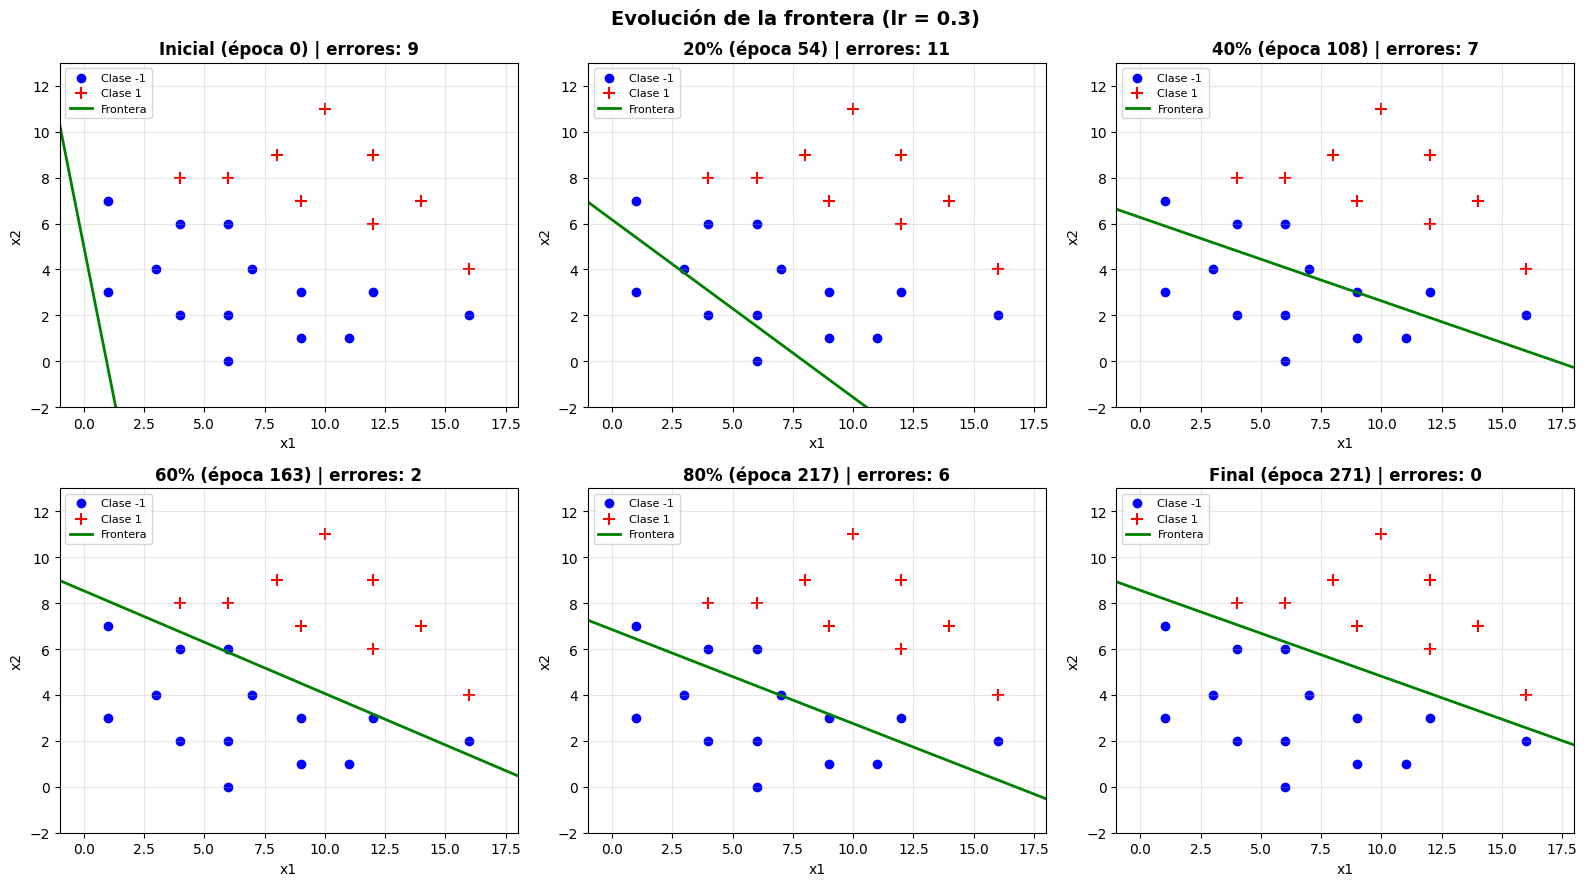

 Epoca         w0       w1       w2   pendiente -w1/w2   corte -w0/w2
     0      0.392   -0.413   -0.078             -5.290          5.023
    54    -25.408    3.187    4.122             -0.773          6.164
   108    -44.608    2.587    7.122             -0.363          6.263
   163    -60.808    3.187    7.122             -0.447          8.538
   217    -73.408    4.387   10.722             -0.409          6.847
   271    -86.608    3.787   10.122             -0.374          8.556


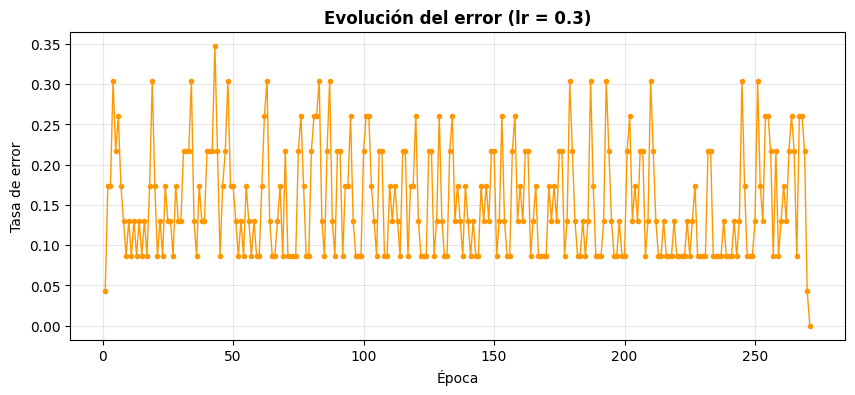

In [21]:
plot_evolution(X, y, resultados[0.3]["W_values"], "Evolución de la frontera (lr = 0.3)")
plot_error(resultados[0.3]["E_values"], "Evolución del error (lr = 0.3)")

#### lr = 0.5

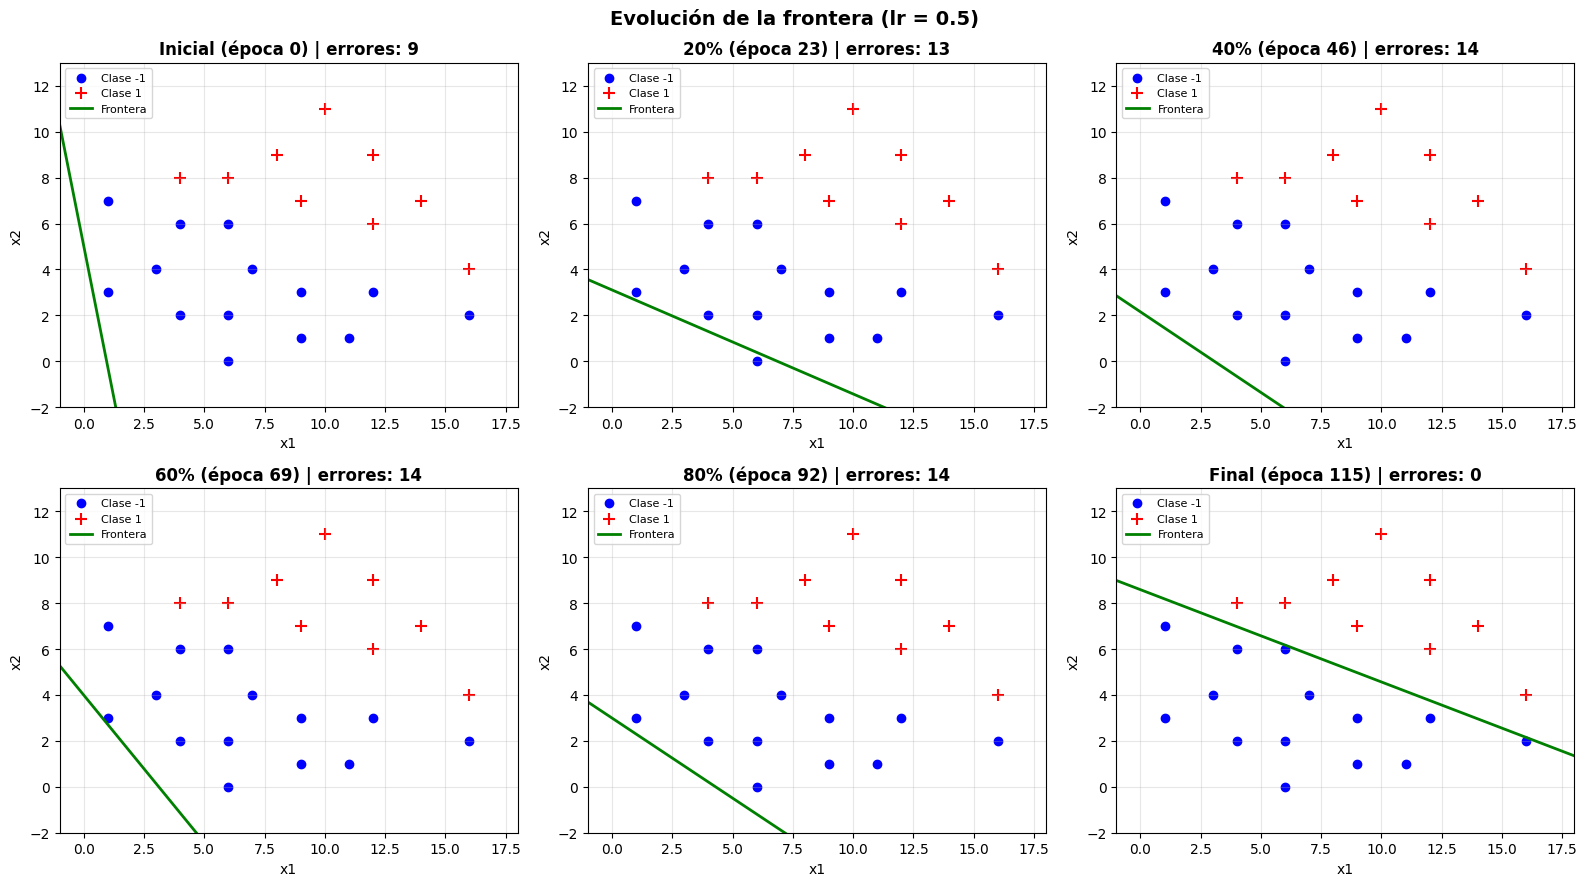

 Epoca         w0       w1       w2   pendiente -w1/w2   corte -w0/w2
     0      0.392   -0.413   -0.078             -5.290          5.023
    23    -24.608    3.587    7.922             -0.453          3.106
    46    -38.608   12.587   17.922             -0.702          2.154
    69    -51.608   16.587   12.922             -1.284          3.994
    92    -62.608   14.587   20.922             -0.697          2.992
   115    -76.608    3.587    8.922             -0.402          8.586


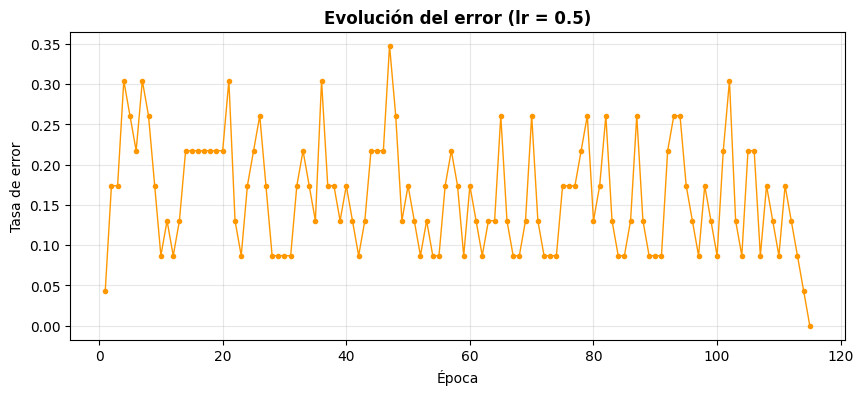

In [22]:
plot_evolution(X, y, resultados[0.5]["W_values"], "Evolución de la frontera (lr = 0.5)")
plot_error(resultados[0.5]["E_values"], "Evolución del error (lr = 0.5)")

#### lr = 0.8

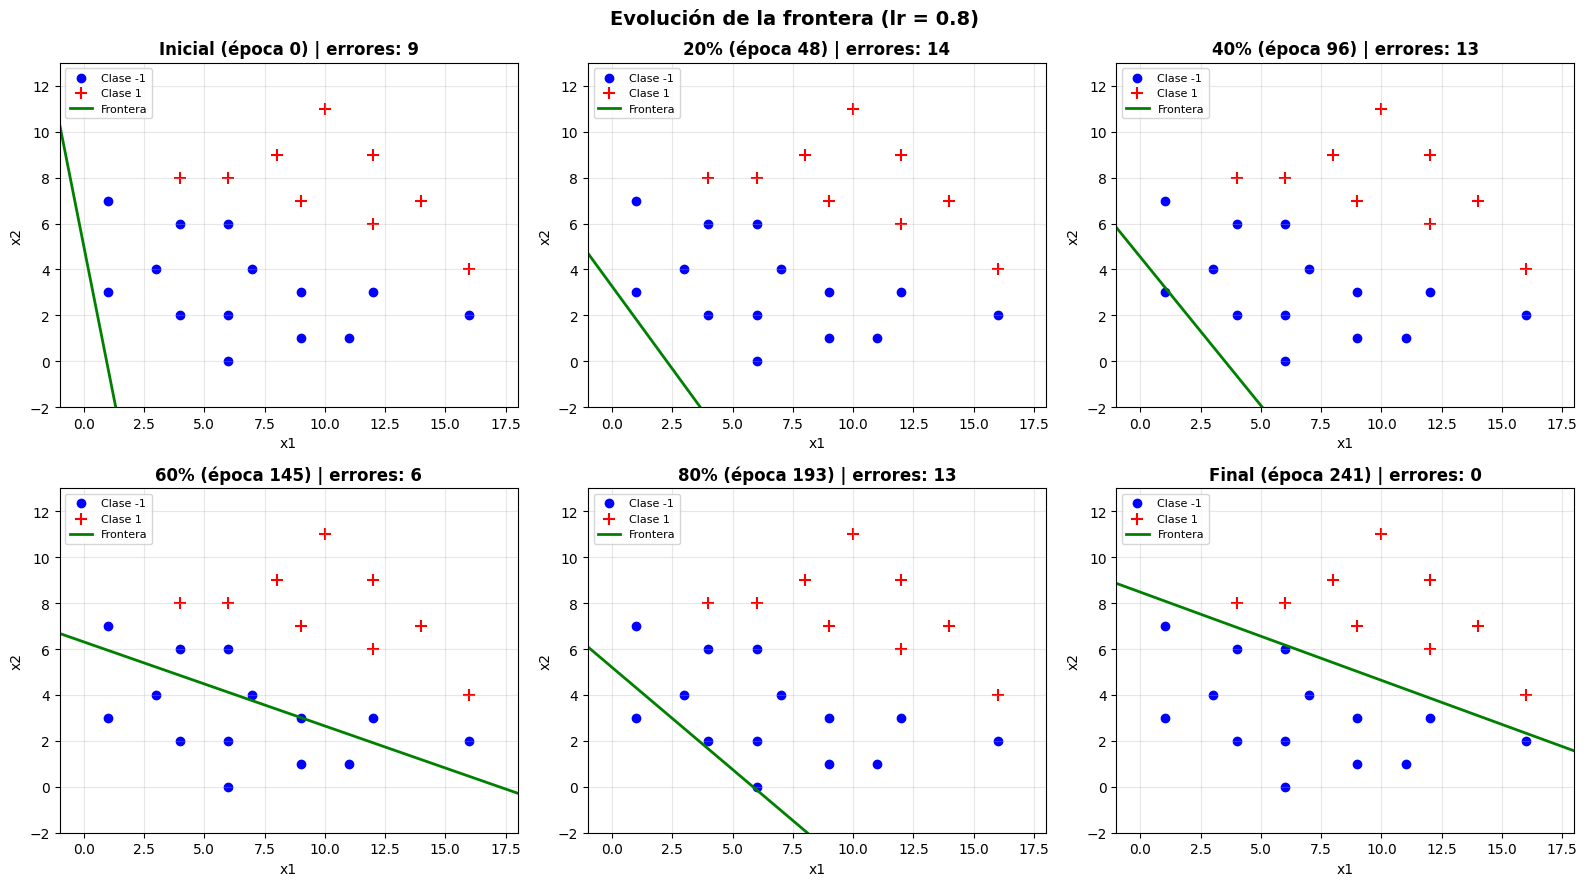

 Epoca         w0       w1       w2   pendiente -w1/w2   corte -w0/w2
     0      0.392   -0.413   -0.078             -5.290          5.023
    48    -57.208   25.187   17.522             -1.437          3.265
    96    -94.008   26.787   20.722             -1.293          4.537
   145   -130.808    7.587   20.722             -0.366          6.313
   193   -166.008   28.387   31.922             -0.889          5.200
   241   -202.808    9.187   23.922             -0.384          8.478


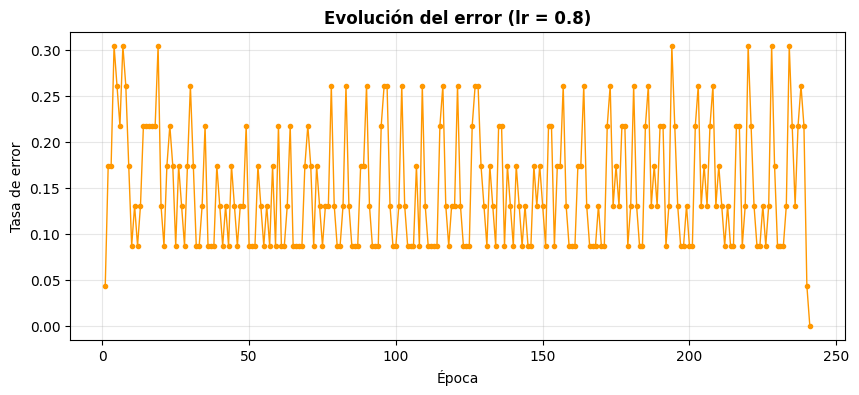

In [23]:
plot_evolution(X, y, resultados[0.8]["W_values"], "Evolución de la frontera (lr = 0.8)")
plot_error(resultados[0.8]["E_values"], "Evolución del error (lr = 0.8)")

**P20. ¿Qué tasa de aprendizaje permitió alcanzar la convergencia con menos épocas? ¿Eso significa necesariamente que es la mejor tasa de aprendizaje?**

*Respuesta:* Con estos pesos iniciales la mas rapida fue lr = 0.5 (115 epocas), contra 241 de lr = 0.8 y 271 de lr = 0.3. Pero eso no la hace la mejor. Al repetir la comparacion con 20 vectores iniciales distintos, lr = 0.8 fue la mas rapida 9 veces, lr = 0.3 6 veces y lr = 0.5 solo 5, asi que el resultado de esta corrida depende de la combinacion con estos pesos. Ademas, las tres llegaron a error 0 con fronteras casi iguales, entonces converger antes no significa que la recta sea mejor para datos nuevos. Para elegir lr habria que comparar varias corridas y evaluar con datos de prueba.

Experimento adicional para justificar P20: se repite la comparación con 20 vectores iniciales distintos (el mismo vector para las tres tasas) y se cuenta cuál converge en menos épocas.

In [24]:
random.seed(0)
ganadores = {0.3: 0, 0.5: 0, 0.8: 0}
print(f"{'Prueba':>6} {'lr=0.3':>8} {'lr=0.5':>8} {'lr=0.8':>8}")
for prueba in range(1, 21):
    w_rand = initialize_weights()
    epocas_lr = {}
    for lr in [0.3, 0.5, 0.8]:
        _, ep, _, _, _ = perceptron_learning(X, y, w_rand.copy(), lr, 1000)
        epocas_lr[lr] = ep
    ganadores[min(epocas_lr, key=epocas_lr.get)] += 1
    print(f"{prueba:>6} {epocas_lr[0.3]:>8} {epocas_lr[0.5]:>8} {epocas_lr[0.8]:>8}")
print("\nVeces que cada lr fue el mas rapido:", ganadores)

Prueba   lr=0.3   lr=0.5   lr=0.8
     1       43      123       43
     2      126      157      157
     3      264      345      123
     4      265      346      111
     5      117      129      299
     6       94       54      357
     7      102      139       78
     8      266      250      127
     9      137       78      264
    10       93      130      129
    11       87      113      124
    12      103      129       43
    13      321      273       44
    14      288      100      264
    15       93      265      102
    16      253      101      345
    17      319      318      105
    18      131      126      265
    19      266      255      117
    20      108      126      106

Veces que cada lr fue el mas rapido: {0.3: 6, 0.5: 5, 0.8: 9}


## Actividad 9.c:

### Tabla comparativa

  lr | Epocas | Actualizaciones | Error final | Pesos finales [w0, w1, w2]
--------------------------------------------------------------------------------
 0.3 |    271 |             949 |         0.0 | [-86.61, 3.79, 10.12]
 0.5 |    115 |             427 |         0.0 | [-76.61, 3.59, 8.92]
 0.8 |    241 |             827 |         0.0 | [-202.81, 9.19, 23.92]


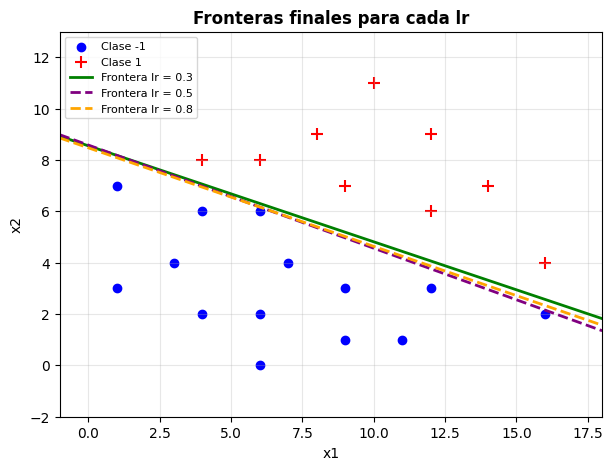

lr = 0.3: x2 = -0.374*x1 + 8.556
lr = 0.5: x2 = -0.402*x1 + 8.586
lr = 0.8: x2 = -0.384*x1 + 8.478


In [25]:
print(f"{'lr':>4} | {'Epocas':>6} | {'Actualizaciones':>15} | {'Error final':>11} | Pesos finales [w0, w1, w2]")
print("-" * 80)
for lr, r in resultados.items():
    pesos = [round(p, 2) for p in r["w"]]
    print(f"{lr:>4} | {r['epocas']:>6} | {r['updates']:>15} | {r['E_values'][-1]:>11} | {pesos}")

fig, ax = plt.subplots(figsize=(7, 5))
perceptron_plot(X, y, resultados[0.3]["w"], "Fronteras finales para cada lr", ax=ax)
ax.lines[0].set_label("Frontera lr = 0.3")
for lr, color in [(0.5, "purple"), (0.8, "orange")]:
    w0, w1, w2 = resultados[lr]["w"]
    ax.plot([-1, 18], [-(w0 + w1 * x1) / w2 for x1 in [-1, 18]], color=color, linewidth=2,
            linestyle="--", label=f"Frontera lr = {lr}")
ax.legend(loc="upper left", fontsize=8)
plt.show()

for lr, r in resultados.items():
    w0, w1, w2 = r["w"]
    print(f"lr = {lr}: x2 = {-w1 / w2:.3f}*x1 + {-w0 / w2:.3f}")

**P21. ¿Los pesos finales son iguales para todas las tasas de aprendizaje? Si son diferentes, ¿por qué pueden producir igualmente una clasificación correcta?**

*Respuesta:* No son iguales: con lr = 0.3 quedan [-86.61, 3.79, 10.12], con 0.5 [-76.61, 3.59, 8.92] y con 0.8 [-202.81, 9.19, 23.92]. Aun asi las tres clasifican todo bien, porque la recta no depende del tamaño de los pesos sino de sus proporciones: la pendiente es $-w_1/w_2$ y el corte es $-w_0/w_2$. Si se multiplican todos los pesos por un mismo numero positivo, la recta no cambia. Por eso las tres fronteras salen casi iguales: $x_2 = -0.374x_1 + 8.556$, $x_2 = -0.402x_1 + 8.586$ y $x_2 = -0.384x_1 + 8.478$. Y como el dataset es separable, hay infinitas rectas que pasan entre las clases, y cualquiera de ellas da 0 errores.

# Conclusiones

1. El perceptron logro separar las dos clases sin errores, pero la recta que encuentra es la primera que funciona, no la mejor. En este caso paso a menos de 0.2 unidades de dos puntos de la clase -1, asi que tener error 0 en entrenamiento no asegura buenas predicciones con datos nuevos.

2. El error no baja de forma continua: oscila casi todo el entrenamiento y al final cae a 0 de golpe, porque cada correccion se hace mirando un solo punto y puede dañar la clasificacion de otros.

3. Como los datos no estan escalados, el bias aprende mucho mas lento que w1 y w2 (se mueve de 1 en 1, mientras que los otros pueden cambiar hasta 16), y esa fue la razon principal de que se necesitaran mas de 100 epocas. Esto se relaciona con lo que vimos en la practica anterior sobre la importancia del escalado.

4. La tasa de aprendizaje no tuvo un efecto consistente: la mas rapida cambio segun los pesos iniciales y las tres llegaron a fronteras casi iguales. Lo que define la recta son las proporciones entre los pesos, no su tamaño.